# Evaluate competing risks predictions

A competing event prevents the event of interest from occurring first. A model therefore
predicts a **cumulative incidence function (CIF) for each cause**,
$F_k(t\mid x)=P(T\leq t,J=k\mid x)$, together with event-free survival
$S(t\mid x)=1-\sum_k F_k(t\mid x)$.

This notebook demonstrates every metric family in `CompetingRisksEvaluator`, in the
order **discrimination → prediction error → calibration**. We fit a small model to
simulated training subjects and evaluate it on an independent test sample. A deliberately
distorted version helps distinguish ranking from probability accuracy.

| Family | Methods demonstrated | Interpretation |
| --- | --- | --- |
| Discrimination | `concordance`, `concordance_per_event`; `auc`, `auc_per_event` | Higher is better; specify the control definition |
| Prediction error | Single-time, multiple-time, and integrated Brier scores, with per-event variants | Lower is better; report the horizon / integration interval |
| Fixed-time calibration | `one_calibration`; `integrated_calibration_index` | Grouped AJ comparison and smoothed Fine–Gray calibration |
| Distributional calibration | `cr_d_calibration(method="integral")` and `method="ks"` | Lower deviation from the identity is better |
| Marginal calibration | `aj_calibration`, `aj_calibration_per_event` | Lower mean-CIF error is better |

**Setup:** run top to bottom in the SurvivalEVAL environment. Install the checkout with
`python -m pip install -e .` from the repository root if needed. This example uses only
existing package dependencies: **no dataset download, R, or optional modelling package**.
All simulated times below are in arbitrary time units.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid
from sklearn.linear_model import PoissonRegressor

from SurvivalEVAL import CompetingRisksEvaluator

plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
})
causes = [1, 2]
horizon = 4.0
follow_up = 10.0

## 1. Simulate independent training and test subjects

One feature $x$ has opposite effects on the two cause-specific hazards:

$$\lambda_1(x)=0.14\exp(0.7x),\qquad
  \lambda_2(x)=0.10\exp(-0.6x).$$

We generate independent exponential latent times conditional on $x$. The first event
determines its cause. Independent random censoring and an administrative boundary at
time 10 determine how much is observed. The evaluator receives only observed times and
labels, not latent event times.

**Labels are integers: `0` = censored, `1` = cause 1, `2` = cause 2.** Keep the competing
events as distinct observed events during evaluation. Replacing every other cause with
zero would incorrectly treat known competing outcomes as censoring.

In [2]:
rng = np.random.default_rng(42)
n_train, n_test = 1500, 1000
features = rng.uniform(-1.5, 1.5, size=(n_train + n_test, 1))
true_rates = np.column_stack([
    0.14 * np.exp(0.7 * features[:, 0]),
    0.10 * np.exp(-0.6 * features[:, 0]),
])
latent_times = rng.exponential(scale=1 / true_rates)
first_event_time = latent_times.min(axis=1)
first_cause = latent_times.argmin(axis=1) + 1
censor_times = np.minimum(rng.exponential(scale=20, size=len(features)), follow_up)
observed_times = np.minimum(first_event_time, censor_times)
observed_causes = np.where(first_event_time <= censor_times, first_cause, 0)

x_train, x_test = features[:n_train], features[n_train:]
train_times, test_times = observed_times[:n_train], observed_times[n_train:]
train_causes, test_causes = observed_causes[:n_train], observed_causes[n_train:]
outcome_counts = pd.DataFrame({
    "Train": np.bincount(train_causes, minlength=3),
    "Test": np.bincount(test_causes, minlength=3),
}, index=["Censored", "Cause 1", "Cause 2"])
outcome_counts

,Train,Test
Censored,273,179
Cause 1,702,453
Cause 2,525,368


## 2. Fit cause-specific exponential models using training data only

We assume $\log\lambda_k(x)=\beta_{0k}+\beta_{1k}x$. For cause $k$, the event count is
$d_{ik}=I(J_i=k)$ and exposure is the observed time $Y_i$. Its negative log-likelihood
is, up to constants,
$\sum_i\{Y_i\lambda_k(x_i)-d_{ik}\log\lambda_k(x_i)\}$.

This is fitted with `PoissonRegressor(alpha=0)` using `count / exposure` as the response
and exposure as `sample_weight`. Every subject contributes exposure until the first
event or censoring, even when that event belongs to the other cause. This training
likelihood differs from relabelling competing events as censored during CIF evaluation.
The weighted-rate construction is also illustrated in
[scikit-learn's Poisson example](https://scikit-learn.org/stable/auto_examples/linear_model/plot_poisson_regression_non_normal_loss.html).

The exponential model is deliberately simple and matches this simulation. It is used
to demonstrate the evaluation API, rather than to recommend a model for real data.

In [3]:
models = []
for cause in causes:
    counts = (train_causes == cause).astype(float)
    model = PoissonRegressor(alpha=0, max_iter=1000, tol=1e-9)
    model.fit(x_train, counts / train_times, sample_weight=train_times)
    models.append(model)
fitted_rates = np.column_stack([model.predict(x_test) for model in models])
pd.DataFrame({
    "Fitted baseline rate": [np.exp(model.intercept_) for model in models],
    "Generating baseline rate": [0.14, 0.10],
    "Fitted feature coefficient": [model.coef_[0] for model in models],
    "Generating feature coefficient": [0.7, -0.6],
}, index=["Cause 1", "Cause 2"])

,Fitted baseline rate,Generating baseline rate,Fitted feature coefficient,Generating feature coefficient
Cause 1,0.144675,0.14,0.693598,0.7
Cause 2,0.103234,0.10,-0.517390,-0.6


## 3. Convert both hazards into valid joint CIF predictions

With constant cause-specific hazards, $\Lambda(x)=\lambda_1(x)+\lambda_2(x)$,

$$F_k(t\mid x)=\frac{\lambda_k(x)}{\Lambda(x)}
  \left(1-\exp[-\Lambda(x)t]\right),\qquad
  S(t\mid x)=\exp[-\Lambda(x)t].$$

Both hazards enter each CIF. In particular, `1 - exp(-lambda_k * t)` is **not** the
cause's cumulative incidence in the presence of competing events.

`pred_cifs` has shape **(subjects, causes, times)**. Cause label `k` is stored at
array index `k - 1`. Curves must be nondecreasing, and their sum must not exceed one.
The shared grid must cover every test subject's observed time. We supply training
outcomes through keyword arguments for training-based IPCW metrics.

We also create **Faster events**, a deliberately distorted model multiplying both fitted
hazards by 1.8. It predicts events earlier while preserving eventual cause probabilities.
It is not refitted or chosen using test outcomes.

In [4]:
prediction_grid = np.linspace(0, follow_up, 201)
evaluators = {}
for name, multiplier in {"Fitted": 1.0, "Faster events": 1.8}.items():
    rates = fitted_rates * multiplier
    total_rate = rates.sum(axis=1)
    event_probs = rates / total_rate[:, None]
    cifs = event_probs[:, :, None] * -np.expm1(-total_rate[:, None, None] * prediction_grid)
    assert cifs.shape == (n_test, 2, len(prediction_grid))
    assert (np.diff(cifs, axis=2) >= 0).all()
    assert ((cifs >= 0) & (cifs <= 1)).all()
    assert (cifs.sum(axis=1) <= 1).all()
    evaluators[name] = CompetingRisksEvaluator(
        cifs, prediction_grid, test_times, test_causes,
        interpolation="Linear", train_event_times=train_times,
        train_event_indicators=train_causes,
    )
evaluator = evaluators["Fitted"]
eventual_probs = fitted_rates / fitted_rates.sum(axis=1, keepdims=True)
np.testing.assert_allclose(eventual_probs.sum(axis=1), 1)
print(f"CIF input shape: {evaluator.pred_cifs.shape}")
print(f"Mean predicted survival at time 10: {1 - evaluator.pred_cifs[:, :, -1].sum(axis=1).mean():.3f}")

CIF input shape: (1000, 2, 201)
Mean predicted survival at time 10: 0.066


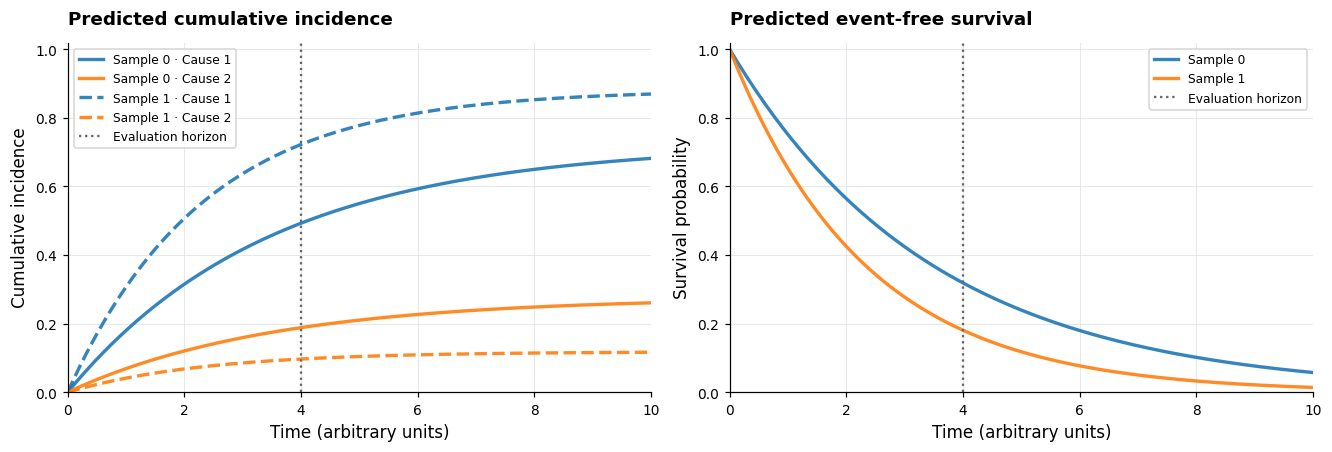

In [5]:
# Colors identify causes and line styles identify subjects in the CIF panel.
selected = [0, 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
evaluator.plot_cif_curves(selected, ax=axes[0], x_label="Time (arbitrary units)")
evaluator.plot_survival_curves(selected, ax=axes[1], x_label="Time (arbitrary units)")
for ax in axes:
    ax.axvline(horizon, color="0.4", linestyle=":", label="Evaluation horizon")
    ax.legend(fontsize=8)
plt.show()

### Extract fixed-time risks and restricted mean time lost

`predict_cifs` evaluates CIF probabilities at requested times. `predict_risks("CIF")`
extracts one fixed-time risk per subject and cause. `predict_rmtl(tau)` integrates
each CIF from zero to $\tau$, giving restricted mean time lost (RMTL) in time units.
`predict_risks("RMTL")` uses the same quantity.

**Larger CIF and RMTL values mean greater risk.** Pass these directly to the competing
risks evaluator; its direction differs from predicted survival times in `PointEvaluator`.

In [6]:
cif_at_horizon = evaluator.predict_cifs(np.array([horizon]))[:, :, 0]
rmtl = evaluator.predict_rmtl(tau=horizon)
np.testing.assert_allclose(cif_at_horizon, evaluator.predict_risks("CIF", target_time=horizon))
np.testing.assert_allclose(rmtl, evaluator.predict_risks("RMTL", tau=horizon))
pd.DataFrame({
    "Cause 1 CIF(4)": cif_at_horizon[:5, 0],
    "Cause 2 CIF(4)": cif_at_horizon[:5, 1],
    "Cause 1 RMTL(4)": rmtl[:5, 0],
    "Cause 2 RMTL(4)": rmtl[:5, 1],
}).rename_axis("Test subject position")

,Cause 1 CIF(4),Cause 2 CIF(4),Cause 1 RMTL(4),Cause 2 RMTL(4)
Test subject position,,,,
0,0.492964,0.188408,1.169863,0.447114
1,0.722570,0.096740,1.838376,0.246129
2,0.285945,0.326126,0.660812,0.753668
3,0.318434,0.298301,0.737120,0.690515
4,0.605019,0.138912,1.476597,0.339026


## 4. Discrimination: competing risks concordance

Concordance compares risk scores at observed cause-specific event anchors. By default
the evaluator uses RMTL; `predict_risk_method="CIF"` instead ranks by risk at a fixed time.
`tau=4` restricts event anchors to times **strictly before 4** and sets the RMTL horizon.
With CIF scoring, `target_time` chooses the risk prediction time and `tau` separately
restricts anchors.

Two control definitions answer different questions:

- **NotCase:** includes subjects with a competing event before or at the anchor,
  as well as subjects observed later.
- **EventFree:** excludes those earlier competing events and uses subjects still
  event-free at the anchor. Censoring exactly at the anchor is included in both definitions.

`method="Naive"` uses unit weights for observable pairs. `method="IPCW"` estimates
inverse censoring weights from training outcomes, assuming independent censoring.
Here censoring was generated independently of both the feature and event times.
`ties="Risk"` gives half credit to risk ties. Higher concordance is better.

In [7]:
concordance_rows = []
for control in ["NotCase", "EventFree"]:
    for method in ["Naive", "IPCW"]:
        for cause in causes:
            score, correct, total = evaluator.concordance_per_event(
                event_of_interest=cause, method=method, control_definition=control,
                tau=horizon, ties="Risk",
            )
            concordance_rows.append({
                "Controls": control, "Method": method, "Cause": cause,
                "Concordance": score, "Concordant weight": correct, "Comparable weight": total,
            })
concordance_table = pd.DataFrame(concordance_rows)
concordance_table.set_index(["Controls", "Method", "Cause"])

Concordance  Concordant weight  Comparable weight
Controls  Method Cause                                                   
NotCase   Naive  1         0.693166      183574.000000      264834.000000
                 2         0.661531      145032.000000      219237.000000
          IPCW   1         0.692693      208511.484616      301015.751141
                 2         0.663427      165198.950186      249008.350322
EventFree Naive  1         0.677748      147057.000000      216979.000000
                 2         0.623655      107664.000000      172634.000000
          IPCW   1         0.677047      165991.540864      245169.975708
                 2         0.624432      121555.409061      194665.589709

### Aggregate across causes explicitly

`reduction="mean"` weights cause-specific concordances equally. `reduction="pooled"`
first adds concordant and comparable pair weights, so causes with more comparable
weight contribute more. These are distinct summaries. `return_details=True` retains
the per-cause results. Undefined cause-specific values are not silently omitted.

In [8]:
mean_c, concordance_details = evaluator.concordance(
    method="IPCW", tau=horizon, reduction="mean", return_details=True
)
pooled_c = evaluator.concordance(method="IPCW", tau=horizon, reduction="pooled")
selected_rows = concordance_table.query("Controls == 'NotCase' and Method == 'IPCW'")
np.testing.assert_allclose(mean_c, selected_rows["Concordance"].mean())
np.testing.assert_allclose(
    pooled_c, selected_rows["Concordant weight"].sum() / selected_rows["Comparable weight"].sum()
)
cif_c = evaluator.concordance(
    method="IPCW", tau=horizon, predict_risk_method="CIF", target_time=horizon
)
pd.Series({"Mean RMTL concordance": mean_c, "Pooled RMTL concordance": pooled_c,
           "Mean fixed-time CIF concordance": cif_c}, name="Value")

Mean RMTL concordance              0.678060
Pooled RMTL concordance            0.679444
Mean fixed-time CIF concordance    0.678060
Name: Value, dtype: float64

## 5. Discrimination: time-dependent AUC / AUROC

At time 4, cases have experienced the selected cause by the horizon. NotCase controls
include competing events by that horizon; EventFree controls exclude them. Both include
subjects observed after the horizon and censorings exactly at it. Earlier censored
subjects have unknown status and are handled through the selected weighting method.

`auc` averages causes equally; `auc_per_event` selects one cause. `auroc` and
`auroc_per_event` are aliases with the same arguments. AUC and concordance differ:
AUC evaluates case/control separation at one horizon, while concordance uses event-time
ordering. Values near 0.5 indicate chance ranking; higher is better.

In [9]:
auc_rows = []
for control in ["NotCase", "EventFree"]:
    for method in ["Naive", "IPCW"]:
        for cause in causes:
            score = evaluator.auc_per_event(
                event_of_interest=cause, target_time=horizon,
                method=method, control_definition=control,
            )
            auc_rows.append({"Controls": control, "Method": method, "Cause": cause, "AUC": score})
mean_auc, auc_details = evaluator.auc(target_time=horizon, method="IPCW", return_details=True)
np.testing.assert_allclose(mean_auc, np.mean(list(auc_details["per_event_scores"].values())))
np.testing.assert_allclose(mean_auc, evaluator.auroc(target_time=horizon, method="IPCW"))
np.testing.assert_allclose(
    auc_details["per_event_scores"][1],
    evaluator.auroc_per_event(event_of_interest=1, target_time=horizon, method="IPCW"),
)
pd.DataFrame(auc_rows).set_index(["Controls", "Method", "Cause"])

AUC
Controls  Method Cause          
NotCase   Naive  1      0.742624
                 2      0.708215
          IPCW   1      0.739373
                 2      0.703846
EventFree Naive  1      0.701699
                 2      0.611250
          IPCW   1      0.700091
                 2      0.612410

## 6. Prediction error: single-time, multiple-time, and integrated Brier scores

For cause $k$, the target is $I(T\leq t,J=k)$, compared with its predicted CIF. A known
competing event is a **negative outcome**, not an unknown censored one. IPCW accounts
for outcomes made unknown by censoring, using the supplied training outcomes. We use
`IPCW_weighted=True` explicitly; fully observed test data use plain scoring automatically.

`brier_score` averages cause-specific errors equally. The per-event variant selects
one cause. `brier_score_multiple_points` returns a curve, and `integrated_brier_score`
averages it over the chosen interval. These averages concern the event causes, not an
additional event-free class. Lower is better.

The explicit integration grid is **[0, 4]**, well within the training follow-up. Report
this interval when comparing IBS values. The assertions below check agreement between
the per-cause, aggregate, and integrated interfaces.

In [10]:
integration_grid = np.linspace(0, horizon, 81)
per_cause_brier = np.stack([
    evaluator.brier_score_multiple_points_per_event(
        target_times=integration_grid, event_of_interest=cause, IPCW_weighted=True
    ) for cause in causes
])
mean_brier_curve = evaluator.brier_score_multiple_points(integration_grid, IPCW_weighted=True)
brier_per_cause = [evaluator.brier_score_per_event(
    event_of_interest=cause, target_time=horizon, IPCW_weighted=True
) for cause in causes]
ibs_per_cause = [evaluator.integrated_brier_score_per_event(
    event_of_interest=cause, target_times=integration_grid, IPCW_weighted=True
) for cause in causes]
mean_brier = evaluator.brier_score(target_time=horizon, IPCW_weighted=True)
mean_ibs = evaluator.integrated_brier_score(target_times=integration_grid, IPCW_weighted=True)
np.testing.assert_allclose(mean_brier_curve, per_cause_brier.mean(axis=0))
np.testing.assert_allclose(mean_brier, np.mean(brier_per_cause))
np.testing.assert_allclose(mean_ibs, np.mean(ibs_per_cause))
np.testing.assert_allclose(mean_ibs, trapezoid(mean_brier_curve, integration_grid) / horizon)
pd.DataFrame({"Brier at 4": [*brier_per_cause, mean_brier],
              "IBS over [0, 4]": [*ibs_per_cause, mean_ibs]},
             index=["Cause 1", "Cause 2", "Equal-weight mean"])

,Brier at 4,"IBS over [0, 4]"
Cause 1,0.194841,0.141126
Cause 2,0.185243,0.129493
Equal-weight mean,0.190042,0.135309


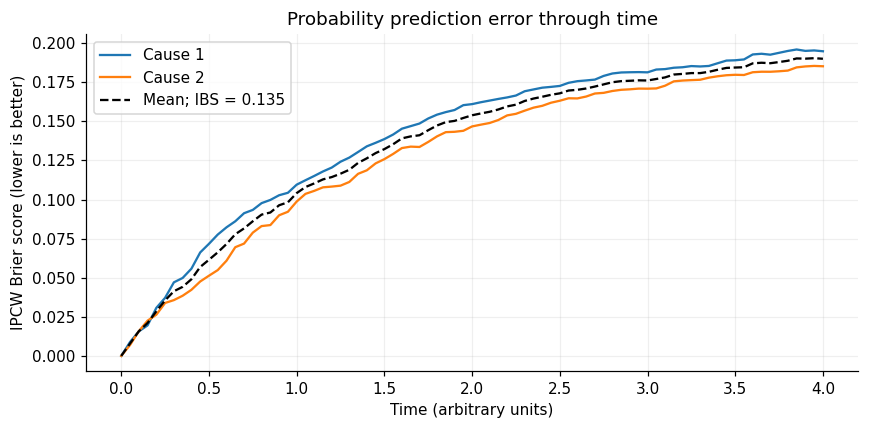

In [11]:
fig, ax = plt.subplots()
for cause, values in zip(causes, per_cause_brier):
    ax.plot(integration_grid, values, label=f"Cause {cause}")
ax.plot(integration_grid, mean_brier_curve, "k--", label=f"Mean; IBS = {mean_ibs:.3f}")
ax.set(xlabel="Time (arbitrary units)", ylabel="IPCW Brier score (lower is better)",
       title="Probability prediction error through time")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Calibration at one horizon: grouped one-calibration

At time 4, divide subjects into five approximately equal-sized predicted-risk groups
(`binning_strategy="C"`). Compare each group's mean CIF with its observed incidence
estimated by **Aalen–Johansen (AJ)**, retaining the competing causes. A Kaplan–Meier
complement with other causes censored would estimate a different quantity.

`adjust_variance=True` uses Greenwood-type AJ variances in a grouped Wald test. Its
p-value is undefined when any group's variance is zero. Fewer or differently defined
groups change the diagnostic. `binning_strategy="H"` instead uses equal-width risk bins.

Points above the diagonal indicate underestimated incidence; points below indicate
overestimated incidence. A small p-value suggests a departure. A large p-value means
the test did not detect one, **not proof that the probabilities are calibrated**.

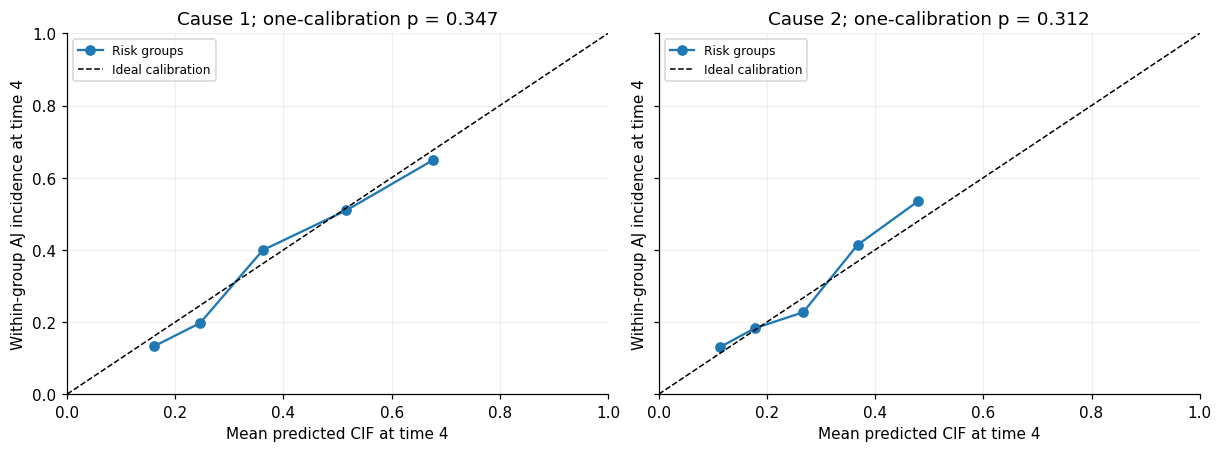

In [12]:
one_p_values = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True)
for ax, cause in zip(axes, causes):
    p_value, observed, predicted = evaluator.one_calibration(
        target_time=horizon, event_of_interest=cause, num_bins=5,
        binning_strategy="C", adjust_variance=True,
    )
    one_p_values[cause] = p_value
    order = np.argsort(predicted)
    ax.plot(np.asarray(predicted)[order], np.asarray(observed)[order], "o-", label="Risk groups")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Ideal calibration")
    ax.set(xlabel="Mean predicted CIF at time 4", ylabel="Within-group AJ incidence at time 4",
           title=f"Cause {cause}; one-calibration p = {p_value:.3g}", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
plt.show()

## 8. Smooth fixed-time calibration: Fine–Gray ICI

Austin et al.'s method fits a Fine–Gray calibration model to evaluation outcomes using
a restricted cubic spline of complementary log-log transformed predicted CIF risk.
Competing-event subjects remain in subdistribution risk sets, with censoring adjustment.
The resulting curve maps predicted to calibrated incidence at the chosen horizon.

The calibration fit estimates censoring from **test outcomes**, unlike the training-based
IPCW discrimination and Brier metrics above. It diagnoses these predictions; it does not
update the prediction model. A recalibration model intended for deployment needs separate
fitting and validation data.

`knots=3` is the total spline knot count. `ICI`, `E50`, `E90`, and `E_max` are the mean,
median, 90th percentile, and maximum absolute differences between predicted and smoothed
calibrated risks across the original subjects. They are errors in probability units,
not p-values. The plotted curve spans the first through 99th predicted-risk percentiles.

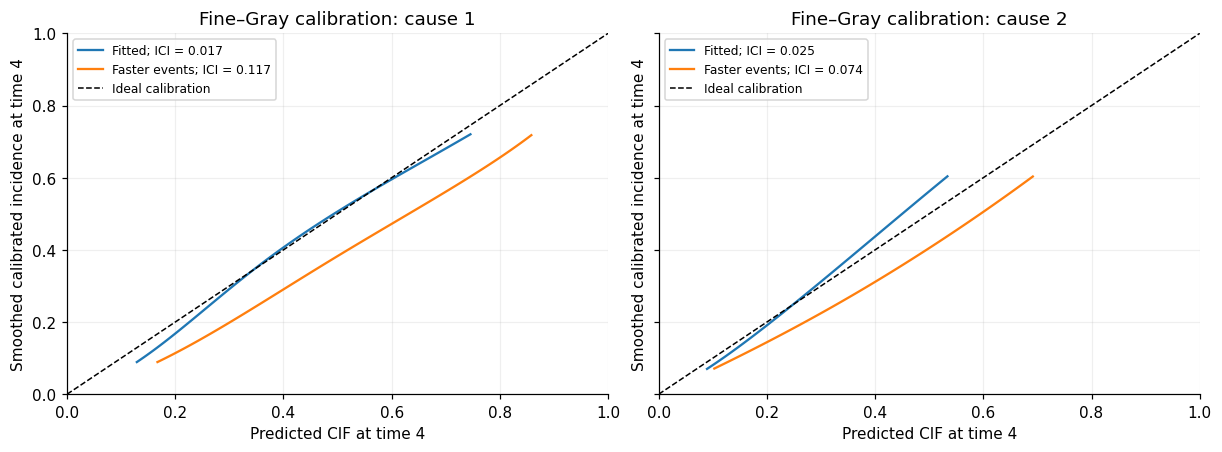

ICI                   E50       E90  \
Model         Cause                                                         
Fitted        1       0.01670111849246993  0.012213022597790557  0.038405   
              2      0.024517423077982946  0.018668711900076775  0.057608   
Faster events 1       0.11685638719751025   0.11543030313596031  0.143411   
              2        0.0742201698126284   0.08308006358893363  0.095346   

                                   E_max  
Model         Cause                       
Fitted        1      0.03994576799393931  
              2      0.07230839126111632  
Faster events 1      0.14420190467198868  
              2       0.0956804170702239

In [13]:
ici_results = {}
ici_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True)
for name, current in evaluators.items():
    ici_results[name] = {}
    for ax, cause in zip(axes, causes):
        result = current.integrated_calibration_index(
            target_time=horizon, event_of_interest=cause, knots=3, draw_figure=False
        )
        ici_results[name][cause] = result
        ax.plot(result["curve"]["grid"], result["curve"]["cal_pred"],
                label=f"{name}; ICI = {result['ICI']:.3f}")
        ici_rows.append({"Model": name, "Cause": cause,
                         **{metric: result[metric] for metric in ["ICI", "E50", "E90", "E_max"]}})
for ax, cause in zip(axes, causes):
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Ideal calibration")
    ax.set(xlabel="Predicted CIF at time 4", ylabel="Smoothed calibrated incidence at time 4",
           title=f"Fine–Gray calibration: cause {cause}", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
plt.show()
pd.DataFrame(ici_rows).set_index(["Model", "Cause"])

## 9. Distributional calibration: CR-D and KS deviations

These metrics assess the whole predicted distribution rather than a single horizon.
They require **eventual cause probabilities** $F_k(\infty)$ in addition to CIFs at
observed times. Here $F_k(\infty)=\lambda_k/\Lambda$ is available from the fitted model.
We pass it explicitly as `pred_event_probs`; the final time-10 CIFs leave appreciable
survival and are not eventual probabilities. The distorted model has the same cause shares.

`method="integral", alpha=2` gives an integrated root squared deviation from the identity.
`method="ks"` gives the maximum grid deviation. Both default to a **sum** over causes;
`mean` and `max` are alternative reductions. Scores are not p-values. KS details include
heuristic per-cause p-values and Bonferroni adjustments; fractional censoring contributions
and estimated probabilities prevent an exact classical KS interpretation.

The diagnostic curves can end above or below one: do not renormalize them, because the
endpoint departure contains information about marginal cause-probability error.

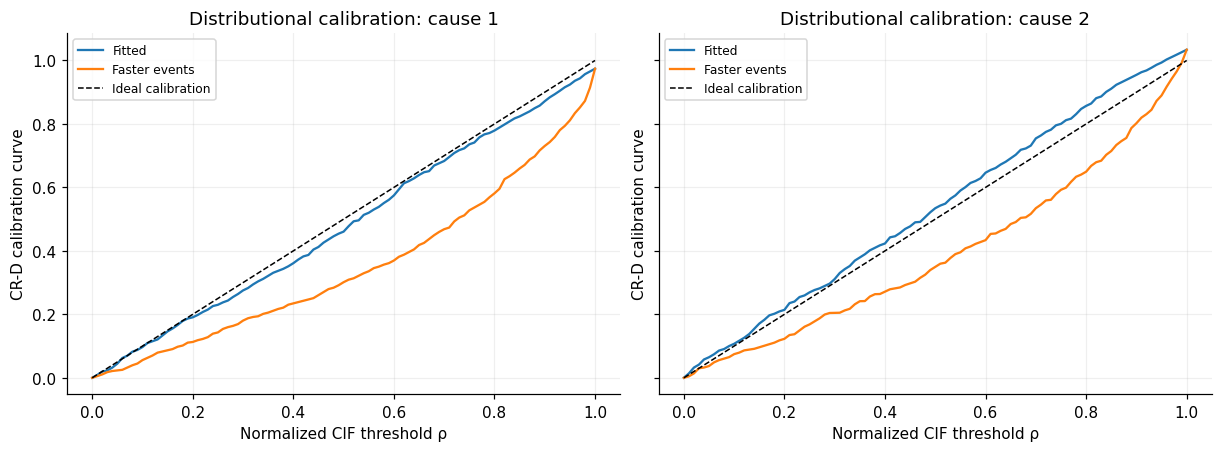

CR-D L2 deviation  KS deviation  Heuristic KS p-value  \
Model         Cause                                                          
Fitted        1               0.023313      0.042857          3.761556e-01   
              2               0.037252      0.063380          1.039844e-01   
Faster events 1               0.166509      0.236574          1.903622e-22   
              2               0.119473      0.174315          3.877248e-10   

                     Bonferroni heuristic p-value  
Model         Cause                                
Fitted        1                      7.523111e-01  
              2                      2.079688e-01  
Faster events 1                      3.807245e-22  
              2                      7.754497e-10

In [14]:
cr_d_results = {}
ks_results = {}
distribution_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True)
for name, current in evaluators.items():
    integral_score, integral_details = current.cr_d_calibration(
        num_bins=100, alpha=2, method="integral", reduction="sum",
        pred_event_probs=eventual_probs, return_details=True,
    )
    ks_score, ks_details = current.cr_d_calibration(
        num_bins=100, method="ks", reduction="sum",
        pred_event_probs=eventual_probs, return_details=True,
    )
    cr_d_results[name] = (integral_score, integral_details)
    ks_results[name] = (ks_score, ks_details)
    for ax, cause in zip(axes, causes):
        curve = integral_details["per_event_details"][cause]
        ax.plot(curve["rho"], curve["calibration_curve"], label=name)
        distribution_rows.append({
            "Model": name, "Cause": cause,
            "CR-D L2 deviation": integral_details["per_event_scores"][cause],
            "KS deviation": ks_details["per_event_scores"][cause],
            "Heuristic KS p-value": ks_details["per_event_details"][cause]["approx_p_value"],
            "Bonferroni heuristic p-value": ks_details["bonferroni_approx_p_values"][cause],
        })
    np.testing.assert_allclose(integral_score, sum(integral_details["per_event_scores"].values()))
for ax, cause in zip(axes, causes):
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Ideal calibration")
    ax.set(xlabel="Normalized CIF threshold ρ", ylabel="CR-D calibration curve",
           title=f"Distributional calibration: cause {cause}")
    ax.legend(fontsize=8)
plt.show()
pd.DataFrame(distribution_rows).set_index(["Model", "Cause"])

## 10. Marginal calibration: mean predicted CIF versus Aalen–Johansen

AJ calibration compares the mean CIF with the marginal AJ estimate through time.
`alpha=2` integrates squared differences and divides by the final retained time;
**there is no square root**, unlike the CR-D L2 norm. `alpha=1` uses absolute error.

By default, prediction-grid points with fewer than 5% of test subjects still at risk
are dropped. Inspect the retained endpoint when comparing models. `reduction="mean"`
averages causes equally; `sum` and `max` are also available. A small marginal error
can conceal errors that cancel across subjects or subgroups.

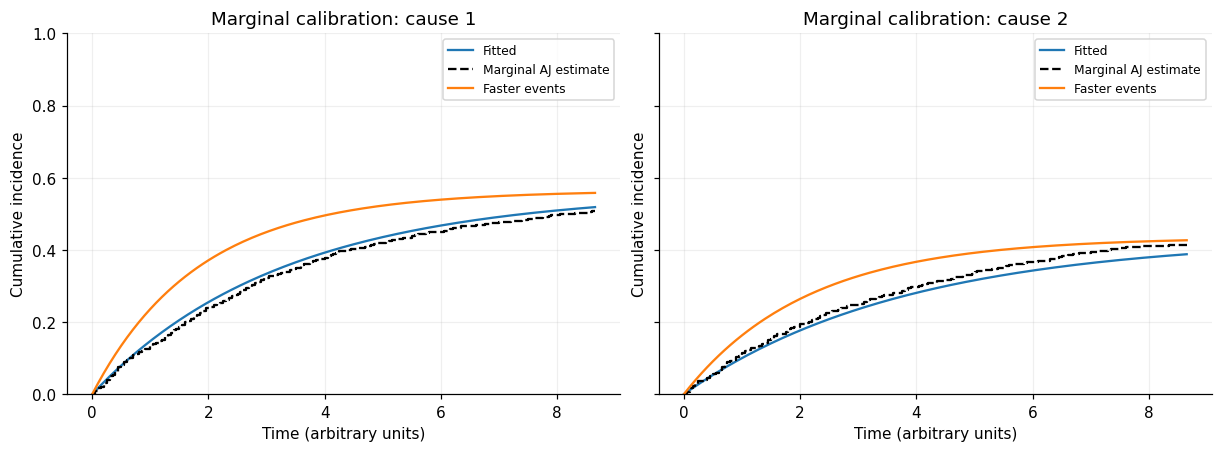

Retained AJ calibration interval: [0, 8.65]


,Fitted,Faster events
Cause,,
1,0.000203,0.00988
2,0.000450,0.00277


In [15]:
aj_results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True)
for name, current in evaluators.items():
    score, details = current.aj_calibration(
        alpha=2, reduction="mean", min_prop_at_risk=0.05, return_details=True
    )
    aj_results[name] = (score, details)
    per_cause = [current.aj_calibration_per_event(
        event_of_interest=cause, alpha=2, min_prop_at_risk=0.05
    ) for cause in causes]
    np.testing.assert_allclose(score, np.mean(per_cause))
    for ax, cause in zip(axes, causes):
        ax.plot(details["time_coordinates"], details["mean_pred_cifs"][cause - 1], label=name)
        if name == "Fitted":
            ax.step(details["time_coordinates"], details["aj_cifs"][cause - 1],
                    where="post", color="black", linestyle="--", label="Marginal AJ estimate")
for ax, cause in zip(axes, causes):
    ax.set(xlabel="Time (arbitrary units)", ylabel="Cumulative incidence",
           title=f"Marginal calibration: cause {cause}", ylim=(0, 1))
    ax.legend(fontsize=8)
plt.show()
print(f"Retained AJ calibration interval: [0, {aj_results['Fitted'][1]['time_coordinates'][-1]:g}]")
pd.DataFrame({name: details["per_event_scores"] for name, (_, details) in aj_results.items()}).rename_axis("Cause")

## 11. Read the metrics together

The simulation and the model distortion below preserve each cause's risk ordering, so
discrimination can remain identical even though predicted probabilities change.
Calibration and Brier scores reveal aspects that ranking scores cannot. Scores have
different scales and aggregations: the table's ICI is an explicitly calculated mean of
two per-cause ICIs; CR-D and KS are sums; AJ and Brier metrics are equal-weight means.

This single reproducible split illustrates the API, not uncertainty or universal model
performance. For a real comparison, fix the horizons, control definitions, weighting,
integration grids, and cause aggregation before comparing models. Check subgroup
calibration and use resampling or external validation to assess uncertainty.

In [16]:
comparison_rows = []
for name, current in evaluators.items():
    comparison_rows.append({
        "Model": name,
        "IPCW concordance ↑": current.concordance(method="IPCW", tau=horizon),
        "IPCW AUC at 4 ↑": current.auc(target_time=horizon, method="IPCW"),
        "Brier at 4 ↓": current.brier_score(target_time=horizon),
        "IBS [0, 4] ↓": current.integrated_brier_score(target_times=integration_grid),
        "Mean per-cause ICI at 4 ↓": np.mean([ici_results[name][k]["ICI"] for k in causes]),
        "CR-D L2 sum ↓": cr_d_results[name][0],
        "KS deviation sum ↓": ks_results[name][0],
        "AJ squared-error mean ↓": aj_results[name][0],
    })
comparison = pd.DataFrame(comparison_rows).set_index("Model")
assert np.isfinite(comparison.to_numpy()).all()
np.testing.assert_allclose(comparison.iloc[0, :2], comparison.iloc[1, :2])
comparison.T

Model,Fitted,Faster events
IPCW concordance ↑,0.678060,0.678060
IPCW AUC at 4 ↑,0.721609,0.721609
Brier at 4 ↓,0.190042,0.199389
"IBS [0, 4] ↓",0.135309,0.144423
Mean per-cause ICI at 4 ↓,0.020609,0.095538
CR-D L2 sum ↓,0.060565,0.285983
KS deviation sum ↓,0.106237,0.410889
AJ squared-error mean ↓,0.000327,0.006325


## References

- Wolbers et al. (2014), [Concordance for prognostic models with competing risks](https://doi.org/10.1093/biostatistics/kxt059).
- Blanche et al. (2013), [Time-dependent AUC for censored event times with competing risks](https://doi.org/10.1002/sim.5958).
- Schoop et al. (2011), [Predictive accuracy in the presence of competing risks](https://doi.org/10.1002/bimj.201000073).
- Austin et al. (2022), [Graphical calibration curves and ICI for competing risk models](https://doi.org/10.1186/s41512-021-00114-6).
- Alberge et al. (2026), [On the Calibration of Survival Models with Competing Risks](https://proceedings.mlr.press/v300/alberge26a.html).